In [1]:
# Figure 2: Journal time series analysis
# Nathan Erickson

In [2]:
# Import modules
import os
import string
import math
import numpy as np
import pandas as pd
import geopandas
import matplotlib as mpl
import matplotlib.pyplot as plt
import cartopy
import seaborn as sns

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

from matplotlib.colors import Normalize,LogNorm

In [3]:
# Set directory structure
base_dir = '' # Fill your directory here
img_dir = os.path.join(base_dir,'FiguresForPaper')

In [4]:
# Assign time series data - Accumulated from journals surveyed
ml_time_series = {
    '2020':240,
    '2021':337,
    '2022':447,
    '2023':620,
    '2024':703,
    '2025':899
}

met_time_series = {
    '2020':3024,
    '2021':3228,
    '2022':2958,
    '2023':3085,
    '2024':2996,
    '2025':3520
}

ml_time_series_df = pd.DataFrame(ml_time_series.values(),ml_time_series.keys(),columns=['Count'])
met_time_series_df = pd.DataFrame(met_time_series.values(),met_time_series.keys(),columns=['Count'])

ml_frac = ml_time_series_df['Count'] / met_time_series_df['Count']

In [5]:
# Load global/regional time series data
data_dir = os.path.join(os.getcwd(),'Data/')
os.chdir(data_dir)

global_regional = pd.read_csv('global_regional_timeseries.csv',index_col='Unnamed: 0')
global_regional

global_ts = global_regional.loc[global_regional['Scope'] == 'Global']
regional_ts = global_regional.loc[global_regional['Scope'] == 'Regional']

global_sum = global_ts.iloc[:,1:-1].sum(axis=0)
regional_sum = regional_ts.iloc[:,1:-1].sum(axis=0)

2020     31
2021     61
2022     94
2023    157
2024    190
2025    246
dtype: int64

In [7]:
# Load WoS query data
os.chdir('WebOfScience Query/')

wos_results = pd.read_csv('WoS Results.csv',skiprows=3)

wos_ml_dict = {'2020':235,
               '2021':446,
               '2022':518,
               '2023':660,
               '2024':956,
               '2025':1348} # From wos_results 'Publication Year'

wos_met_dict = {'2020':18470,
                '2021':20517,
                '2022':19855,
                '2023':19864,
                '2024':21298,
                '2025':24406}

C:\Users\eric0051\AppData\Local\Temp\ipykernel_11396\4173491995.py:5: DtypeWarning: Columns (2,3,7,8,10,11,17,18) have mixed types. Specify dtype option on import or set low_memory=False.
  wos_results = pd.read_csv('WoS Results.csv',skiprows=3)


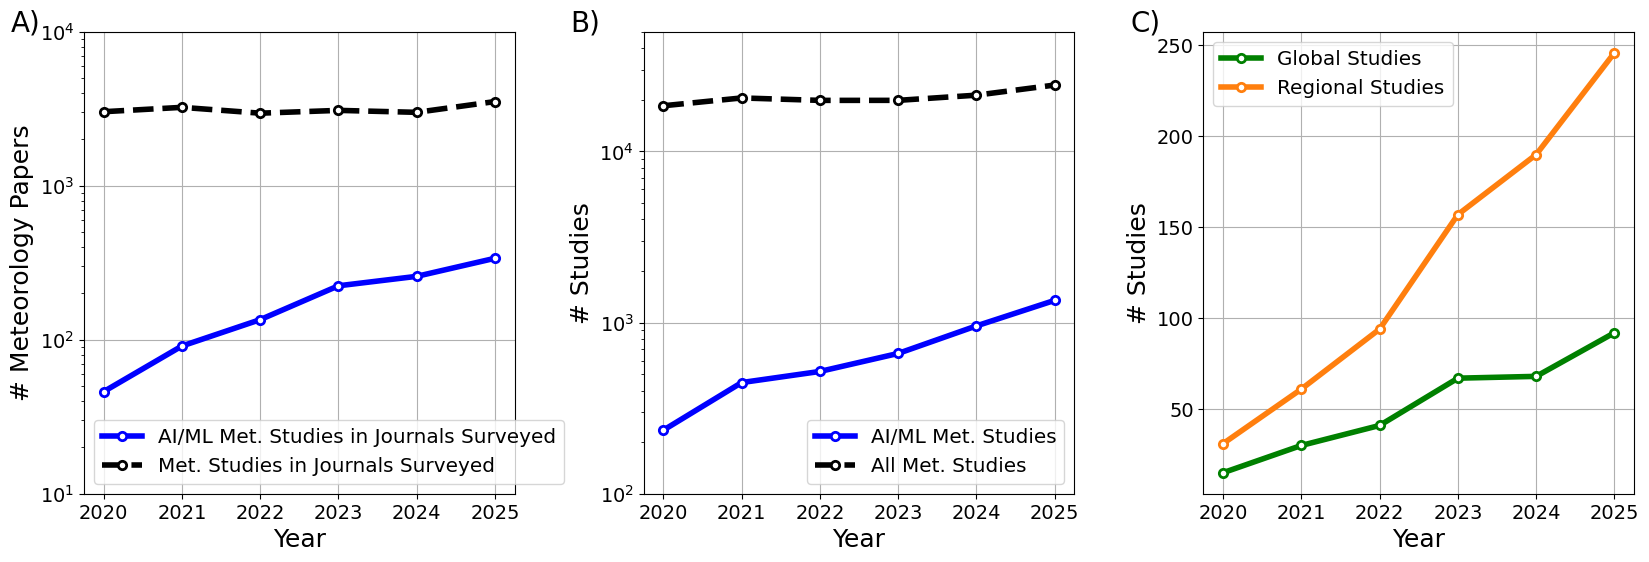

In [26]:
# Super basic plot of time series of ML studies
fig,axes = plt.subplots(1,3,figsize=(20,6))
plt.subplots_adjust(wspace=0.3)

ax = axes[0]
ax2 = axes[1]
ax3 = axes[2]

### FIRST SUBPLOT ###
# - ML / meteorology papers from journals we surveyed
#ax.bar(time_series_df.index,time_series_df['Count'])
#plotted = ml_time_series_df['Count']
plotted = global_sum+regional_sum
plotted_met = met_time_series_df['Count']
ml_frac = plotted/plotted_met

ax.plot(ml_time_series_df.index,plotted,color='blue',marker='o',linewidth=4,
           markeredgecolor='blue',markeredgewidth=2,
           markerfacecolor=(1,1,1,1),label='AI/ML Met. Studies in Journals Surveyed',zorder=3)
ax.plot(met_time_series_df.index,met_time_series_df['Count'],color='black',linestyle='--',marker='o',linewidth=4,
        markeredgecolor='black',markeredgewidth=2,
        markerfacecolor=(1,1,1,1),label='Met. Studies in Journals Surveyed',zorder=3)

#ax.set_title('Trend in ML Meteorology Studies',fontsize=14,fontweight='bold',zorder=2)
ax.set_xlabel('Year',fontsize=18)
ax.set_ylabel('# Meteorology Papers',fontsize=18)

lines, labels = ax.get_legend_handles_labels()

ax.legend(lines, labels, loc='lower left',fontsize='x-large')

ax.tick_params(axis='both',labelsize=14)

ax.set_ylim(10,10000)
ax.set_yscale('log')

### SECOND SUBPLOT ###
# Plot the Web of Science Stats
ax2.plot(wos_ml_dict.keys(),wos_ml_dict.values(),color='blue',marker='o',linewidth=4,
        markeredgecolor='blue',markeredgewidth=2,
        markerfacecolor=(1,1,1,1),label='AI/ML Met. Studies')
ax2.plot(wos_met_dict.keys(),wos_met_dict.values(),color='black',linestyle='--',marker='o',linewidth=4,
        markeredgecolor='black',markeredgewidth=2,
        markerfacecolor=(1,1,1,1),label='All Met. Studies')

ax2.set_xlabel('Year',fontsize=18)
ax2.set_ylabel('# Studies',fontsize=18)

ax2.legend(fontsize='x-large')

ax2.tick_params(axis='both',labelsize=14)

ax2.set_ylim(100,50000)
ax2.set_yscale('log')

### THIRD SUBPLOT ###
# Plot the global vs. regional breakdown
ax3.plot(global_sum.index,global_sum,color='green',marker='o',linewidth=4,
        markeredgecolor='green',markeredgewidth=2,
        markerfacecolor=(1,1,1,1),label='Global Studies')
ax3.plot(regional_sum.index,regional_sum,color='tab:orange',marker='o',linewidth=4,
        markeredgecolor='tab:orange',markeredgewidth=2,
        markerfacecolor=(1,1,1,1),label='Regional Studies')

ax3.set_xlabel('Year',fontsize=18)
ax3.set_ylabel('# Studies',fontsize=18)

ax3.tick_params(axis='both',labelsize=14)

ax3.legend(fontsize='x-large')

# Label with lettering
for idx,axis in enumerate(axes.flatten()):
    axis.grid(zorder=-1)
    axis.text(-0.17,1,f'{string.ascii_uppercase[idx]})',fontsize=20,transform=axis.transAxes)

In [ ]:
os.chdir(img_dir)
#fig.savefig('Fig2.jpg',bbox_inches='tight',dpi=300)
print(os.getcwd())